Distance and the Curse of Dimensionality

Persiapan Dataset

Setiap fitur kimia merupakan satu dimensi. Dataset WineQT memiliki banyak fitur dengan satuan dan rentang nilai yang berbeda, sehingga fitur perlu distandardisasi sebelum jarak dihitung.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import pairwise_distances

data = pd.read_csv("data/WineQT.csv")

print("Ukuran dataset:", data.shape)
display(data.head())

Ukuran dataset: (1143, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


Memilih dan Menstandardisasi Fitur

Kolom `Id` hanya identitas data dan `quality` merupakan label kualitas. Keduanya tidak dimasukkan dalam pengukuran jarak. StandardScaler membuat setiap fitur memiliki skala yang sebanding.

In [2]:
X = data.drop(columns=["Id", "quality"])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Jumlah fitur:", X_scaled.shape[1])
print("Jumlah observasi:", X_scaled.shape[0])

Jumlah fitur: 11
Jumlah observasi: 1143


Mengamati Jarak pada Jumlah Dimensi Berbeda

Pada ruang berdimensi tinggi, jarak antar titik cenderung semakin mirip (konsentrasi jarak). Di bawah ini kita membandingkan jarak pasangan data dengan 2, 5, dan seluruh fitur. Sampel pasangan digunakan agar perhitungan tetap ringan.

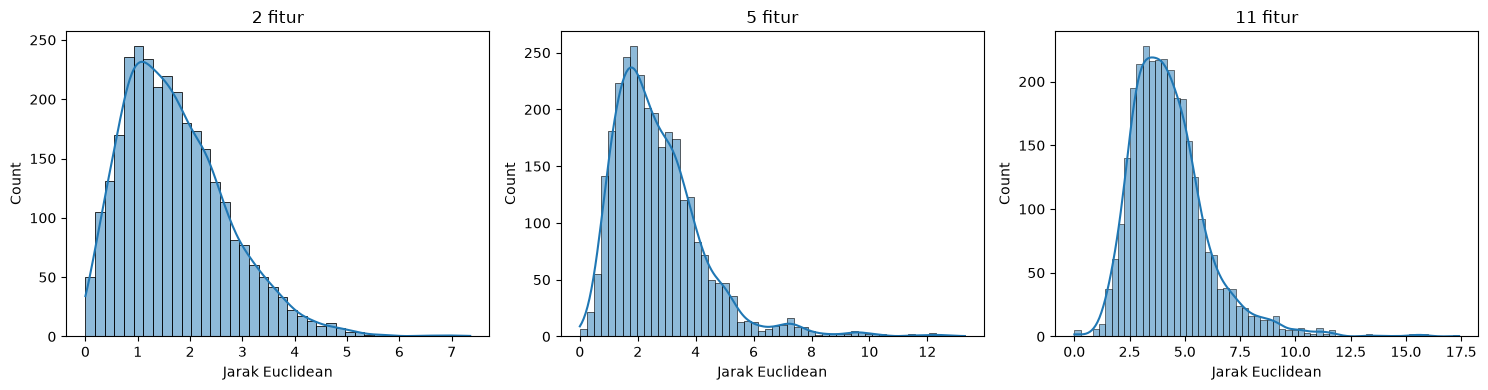

In [3]:
rng = np.random.default_rng(42)
n_pairs = 3000
n_rows = X_scaled.shape[0]

idx_a = rng.integers(0, n_rows, n_pairs)
idx_b = rng.integers(0, n_rows, n_pairs)

dimensions = [2, 5, X_scaled.shape[1]]
distance_results = {}

for n_features in dimensions:
    distances = np.linalg.norm(
        X_scaled[idx_a, :n_features] - X_scaled[idx_b, :n_features],
        axis=1
    )
    distance_results[n_features] = distances

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (n_features, distances) in zip(axes, distance_results.items()):
    sns.histplot(distances, kde=True, ax=ax)
    ax.set_title(f"{n_features} fitur")
    ax.set_xlabel("Jarak Euclidean")

plt.tight_layout()
plt.show()

Bandingkan bentuk distribusi pada grafik. Ketika jumlah dimensi bertambah, rentang jarak biasanya ikut berubah dan jarak antar pasangan dapat menjadi relatif lebih seragam. Ini salah satu alasan mengapa konsep kedekatan menjadi lebih sulit dimanfaatkan pada dimensi tinggi.

Ringkasan Distribusi Jarak

Koefisien variasi (simpangan baku dibagi rata-rata) membantu melihat seberapa besar variasi jarak relatif terhadap rata-ratanya. Nilai yang lebih kecil menunjukkan jarak relatif lebih seragam.

In [4]:
summary = []

for n_features, distances in distance_results.items():
    summary.append({
        "Jumlah fitur": n_features,
        "Rata-rata jarak": distances.mean(),
        "Simpangan baku": distances.std(),
        "Koefisien variasi": distances.std() / distances.mean()
    })

display(pd.DataFrame(summary).round(3))

,Jumlah fitur,Rata-rata jarak,Simpangan baku,Koefisien variasi
0,2,1.719,1.007,0.586
1,5,2.692,1.589,0.590
2,11,4.295,1.783,0.415


Mengamati Jarak Tetangga Terdekat

Kita juga dapat melihat jarak ke tetangga terdekat untuk setiap data. Perbandingan ini memperlihatkan bagaimana jarak minimum berubah ketika lebih banyak fitur digunakan.

In [5]:
nearest_summary = []

for n_features in dimensions:
    subset = X_scaled[:, :n_features]
    distances = pairwise_distances(subset, metric="euclidean")
    np.fill_diagonal(distances, np.inf)
    nearest = distances.min(axis=1)

    nearest_summary.append({
        "Jumlah fitur": n_features,
        "Rata-rata jarak tetangga terdekat": nearest.mean(),
        "Median jarak tetangga terdekat": np.median(nearest)
    })

display(pd.DataFrame(nearest_summary).round(3))

,Jumlah fitur,Rata-rata jarak tetangga terdekat,Median jarak tetangga terdekat
0,2,0.054,0.056
1,5,0.325,0.284
2,11,0.891,0.945


Cara Mengatasi Curse of Dimensionality

Beberapa pendekatan yang umum digunakan:
- Feature selection: memilih fitur yang paling relevan dan mengurangi fitur yang tidak diperlukan.
- Dimensionality reduction: menggunakan teknik seperti PCA untuk merangkum informasi ke beberapa komponen.
- Menambah data: pada kondisi tertentu, lebih banyak observasi dapat membantu mewakili ruang fitur yang luas.
- Evaluasi metrik jarak: tidak selalu mengandalkan Euclidean; pilihan metrik perlu disesuaikan dengan karakteristik data.

Kesimpulan: semakin banyak fitur, ruang data menjadi semakin luas dan konsep jarak dapat kehilangan daya pembeda. Karena itu, pemilihan fitur, scaling, dan pemilihan metode yang tepat penting terutama untuk algoritma berbasis jarak seperti KNN dan K-Means.

Sumber Dataset

Kaggle - Wine Quality Dataset

Simpan file sebagai `data/WineQT.csv` sebelum menjalankan notebook.